# Convolutional Neural Networks (CNNs) for Image Recognition

In [ ]:
# Importing libraries

import tensorflow as tf
from keras.datasets import mnist
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, ReLU
import matplotlib.pyplot as plt

In [ ]:
# Importing Data

(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
# to Black-White picture

X_train = X_train.reshape(-1, 28, 28, 1) / 255
X_test = X_test.reshape(-1, 28, 28, 1) / 255

In [5]:
X_train.shape

(60000, 28, 28, 1)

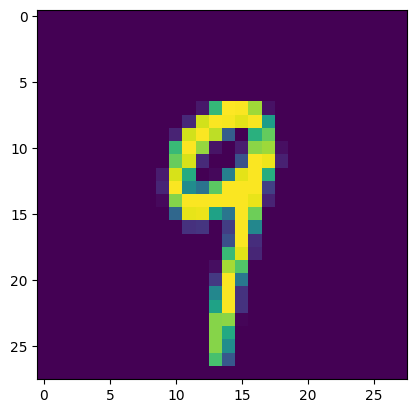

In [6]:
plt.imshow(X_train[600])

In [7]:
# Model Training

cnn_model = Sequential(
    [
        Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3)),
        ReLU(),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3)),
        ReLU(),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(128, activation="relu"),
        Dense(64, activation="relu"),
        Dense(32, activation="relu"),
        Dense(10, activation="softmax"),
    ]
)

/Users/odoker/.data_env/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
# to eliminate the warning, We can modify the code as follows

from keras import layers

cnn_model = Sequential(
    [
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3)),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3)),
        layers.ReLU(),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(32, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ]
)

In [9]:
cnn_model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

In [10]:
# Model Training
# For EPOCHS = 10 and BATCH_SIZE = 64

cnn_model.fit(
    X_train, y_train, epochs=10, batch_size=64, validation_data=(X_test, y_test)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9044 - loss: 0.3056 - val_accuracy: 0.9710 - val_loss: 0.0963
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9737 - loss: 0.0867 - val_accuracy: 0.9787 - val_loss: 0.0708
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9815 - loss: 0.0593 - val_accuracy: 0.9854 - val_loss: 0.0518
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9855 - loss: 0.0460 - val_accuracy: 0.9836 - val_loss: 0.0551
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9882 - loss: 0.0378 - val_accuracy: 0.9847 - val_loss: 0.0545
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9904 - loss: 0.0311 - val_accuracy: 0.9867 - val_loss: 0.0473
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9912 - loss: 0.0276 - val_accuracy: 0.9778 - val_loss: 0.0732
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9928 - loss: 0.0223 - val_accuracy: 0.

In [11]:
# Saving the model

cnn_model.save("cnn.keras")

In [ ]:
# Filter Visualization
# For first Conv2D layer
# 0 ->    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
# 1 ->    MaxPooling2D((2, 2)),
# 2 ->    Conv2D(64, (3, 3)),
# 3 ->    ReLU(),
# 4 ->    MaxPooling2D((2, 2)),
# 5 ->    Conv2D(128, (3, 3)),
# 6 ->    ReLU(),
# 7 ->    MaxPooling2D((2, 2)),
# 8 ->    Flatten(),
# 9 ->    Dense(128, activation="relu"),
# 10 ->   Dense(64, activation="relu"),
# 11 ->   Dense(32, activation="relu"),
# 12 ->   Dense(10, activation="softmax"),

layer_index = 0

layer = cnn_model.layers[layer_index]

In [13]:
filters, biases = layer.get_weights()

In [14]:
n_filters = filters.shape[3]

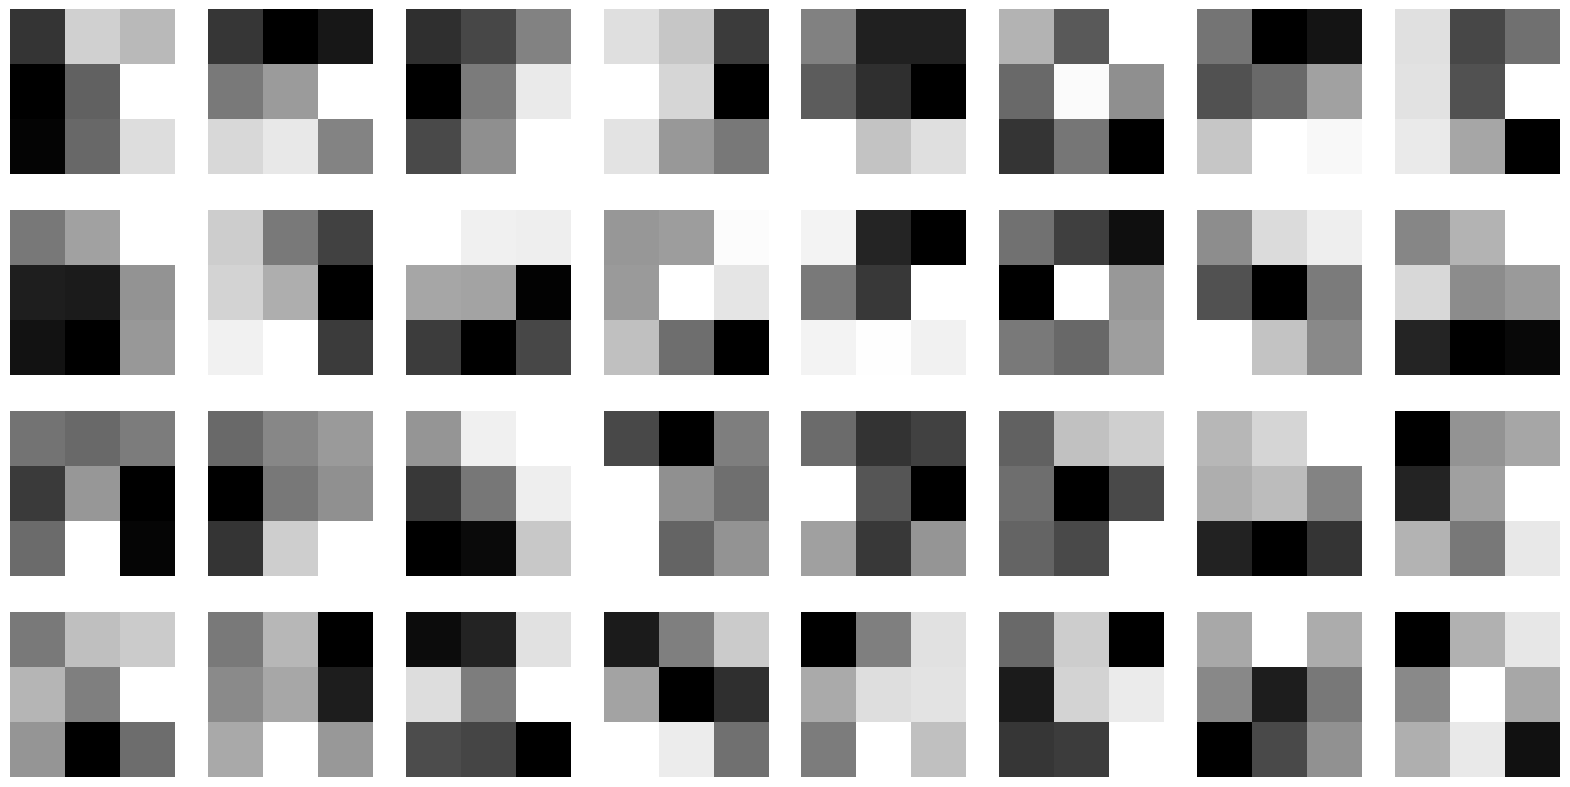

In [15]:
plt.figure(figsize=(20, 10))
for i in range(n_filters):
    f = filters[:, :, :, i]
    plt.subplot(4, 8, i + 1)
    plt.imshow(f[:, :, 0], cmap="gray")
    plt.axis("off")
plt.show()

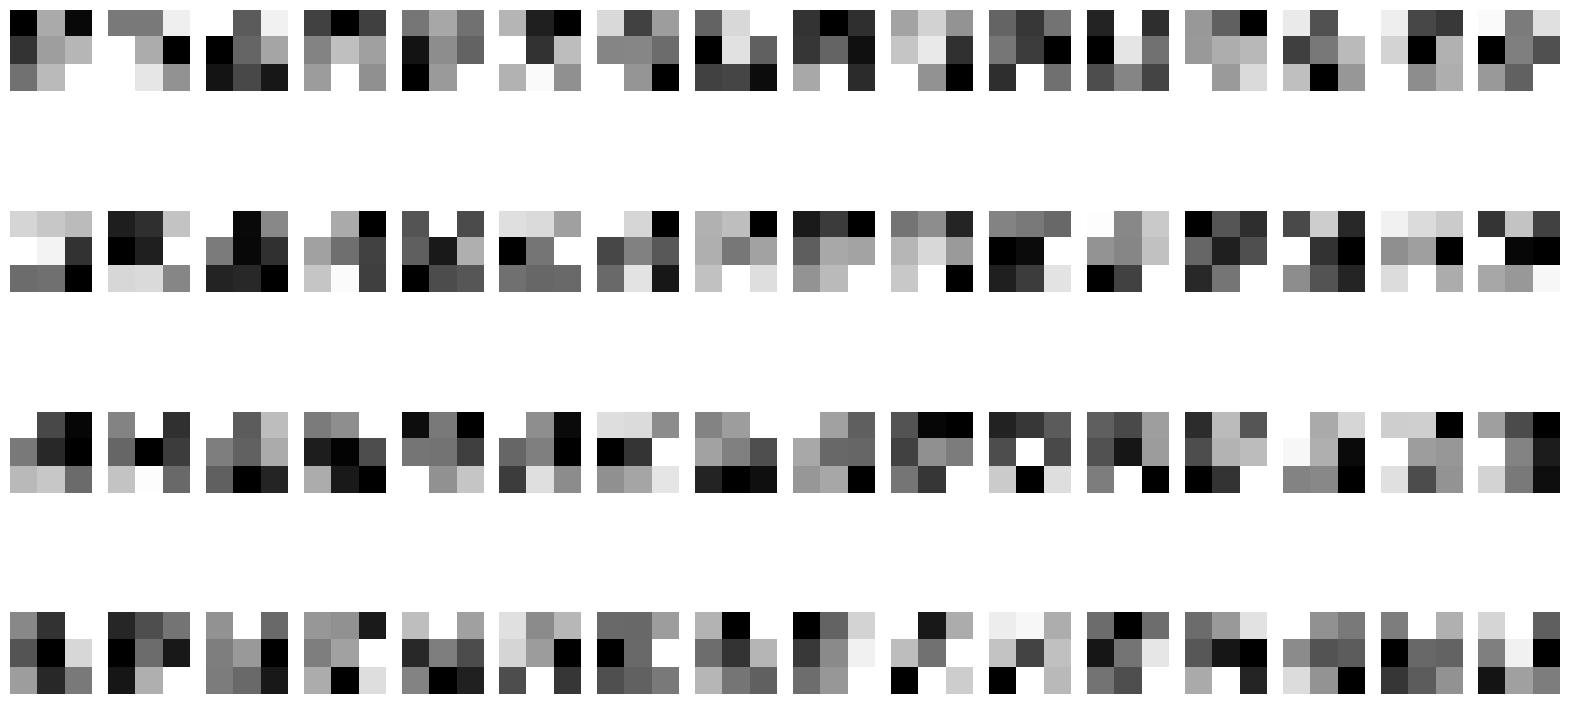

In [ ]:
# Filter Visualization
# For second Conv2D layer
# 0 ->    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
# 1 ->    MaxPooling2D((2, 2)),
# 2 ->    Conv2D(64, (3, 3)),
# 3 ->    ReLU(),
# 4 ->    MaxPooling2D((2, 2)),
# 5 ->    Conv2D(128, (3, 3)),
# 6 ->    ReLU(),
# 7 ->    MaxPooling2D((2, 2)),
# 8 ->    Flatten(),
# 9 ->    Dense(128, activation="relu"),
# 10 ->   Dense(64, activation="relu"),
# 11 ->   Dense(32, activation="relu"),
# 12 ->   Dense(10, activation="softmax"),

layer_index = 2

layer = cnn_model.layers[layer_index]

filters, biases = layer.get_weights()
n_filters = filters.shape[3]
plt.figure(figsize=(20, 10))
for i in range(n_filters):
    f = filters[:, :, :, i]
    plt.subplot(4, 16, i + 1)
    plt.imshow(f[:, :, 0], cmap="gray")
    plt.axis("off")
plt.show()

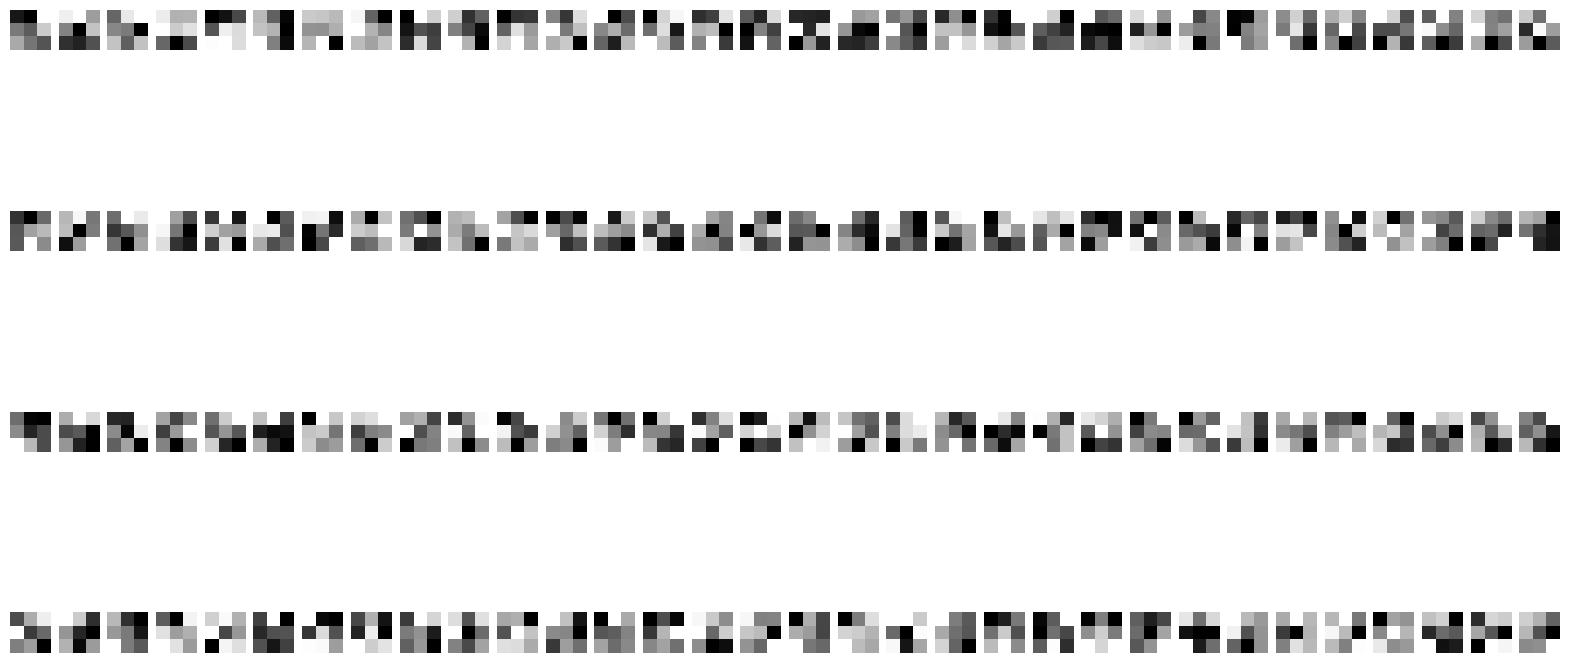

In [17]:
# Filter Visualization
# For third Conv2D layer
# 0 ->    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
# 1 ->    MaxPooling2D((2, 2)),
# 2 ->    Conv2D(64, (3, 3)),
# 3 ->    ReLU(),
# 4 ->    MaxPooling2D((2, 2)),
# 5 ->    Conv2D(128, (3, 3)),
# 6 ->    ReLU(),
# 7 ->    MaxPooling2D((2, 2)),
# 8 ->    Flatten(),
# 9 ->    Dense(128, activation="relu"),
# 10 ->   Dense(64, activation="relu"),
# 11 ->   Dense(32, activation="relu"),
# 12 ->   Dense(10, activation="softmax"),

layer_index = 5

layer = cnn_model.layers[layer_index]

filters, biases = layer.get_weights()
n_filters = filters.shape[3]
plt.figure(figsize=(20, 10))
for i in range(n_filters):
    f = filters[:, :, :, i]
    plt.subplot(4, 32, i + 1)
    plt.imshow(f[:, :, 0], cmap="gray")
    plt.axis("off")
plt.show()

In [18]:
# Real-time testing

from PIL import Image
import numpy as np

In [19]:
def predict_image(image_path):
    img = Image.open(image_path).convert("L")
    img = img.resize((28, 28))
    img_array = np.array(img)

    img_array = img_array.reshape(-1, 28, 28, 1) / 255

    prediction = cnn_model.predict(img_array)

    predicted_number = np.argmax(prediction)

    print(predicted_number)

    plt.imshow(img, cmap="grey")
    plt.title(f"Prediction: {predicted_number}")
    plt.axis("off")
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
6


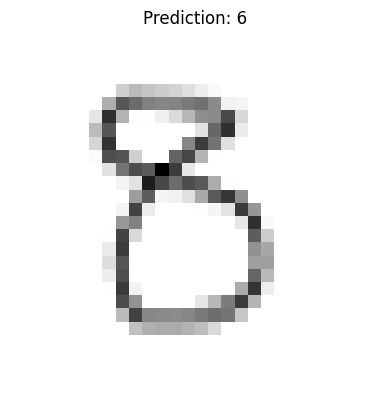

In [23]:
entry = input("Enter the file path of the image you want to predict.")

predict_image(entry)

In [ ]:
# Model Training
# For EPOCHS = 100 and BATCH_SIZE = 32

cnn_model.fit(
    X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test)
)


Epoch 1/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9904 - loss: 0.0299 - val_accuracy: 0.9874 - val_loss: 0.0464
Epoch 2/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9931 - loss: 0.0221 - val_accuracy: 0.9873 - val_loss: 0.0524
Epoch 3/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9937 - loss: 0.0218 - val_accuracy: 0.9883 - val_loss: 0.0465
Epoch 4/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9949 - loss: 0.0180 - val_accuracy: 0.9867 - val_loss: 0.0522
Epoch 5/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9950 - loss: 0.0167 - val_accuracy: 0.9886 - val_loss: 0.0528
Epoch 6/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9961 - loss: 0.0136 - val_accuracy: 0.9859 - val_loss: 0.0586
Epoch 7/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9959 - loss: 0.0137 - val_accuracy: 0.9868 - val_loss: 0.0541
Epoch 8/100
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9962 - loss: 0

In [ ]:
# Saving the model

cnn_model.save("cnn_model_2.keras")


In [ ]:
# Real-time testing


def predict_image(image_path):
    img = Image.open(image_path).convert("L")
    img = img.resize((28, 28))
    img_array = np.array(img)

    img_array = img_array.reshape(-1, 28, 28, 1) / 255

    prediction = cnn_model.predict(img_array)

    predicted_number = np.argmax(prediction)

    print(predicted_number)

    plt.imshow(img, cmap="grey")
    plt.title(f"Prediction: {predicted_number}")
    plt.axis("off")
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
1


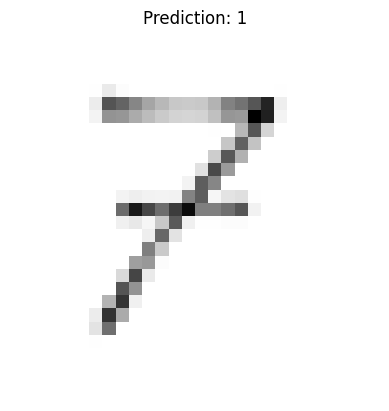

In [27]:
entry = input("Enter the file path of the image you want to predict.")

predict_image(entry)